# Part 0: Mind-Reader, the bot that reads your next throw

**Mind-Reader** plays rock-paper-scissors against you through your webcam. The bot is called **CHANAKYA**, after the ancient Indian strategist known for reading his opponents.

It reads you in two ways, both with scikit-learn:
- **The eyes** look at your hand and name the gesture: rock, paper or scissors.
- **The brain** looks at the last rounds of the game and predicts your next move, so CHANAKYA can play the move that beats it.

This notebook trains both, then plays a live game, and ends with what we learned.

## Setup
On Colab this cell downloads the project and installs MediaPipe, the library that finds the hand. On a laptop it only finds the project folder.
Both ways, it makes sure the hand model file is there (about 8 MB, checked against its sha256 fingerprint).

In [1]:
import importlib
import importlib.metadata as metadata
import os
import subprocess
import sys
import warnings

BRANCH = "build/mind-reader"  # becomes "main" once the branch is merged
REPO_URL = "https://github.com/Krishpotanwar/mind-reader.git"

if "google.colab" in sys.modules:
    if not os.path.isdir("/content/mind-reader"):
        clone_cmd = ["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, "/content/mind-reader"]
        if subprocess.run(clone_cmd, capture_output=True).returncode != 0:
            print("Couldn't download the project: check the internet and re-run")
            raise SystemExit(1)
    os.chdir("/content/mind-reader")  # an absolute path, so running this cell twice is safe
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mediapipe==1.1.1"], check=True)
    importlib.invalidate_caches()
    loaded = sys.modules["numpy"].__version__ if "numpy" in sys.modules else None
    if loaded and loaded != metadata.version("numpy"):  # pip changed numpy after this session had already loaded it
        print(f"RESTART NEEDED: numpy {loaded} is already loaded but numpy {metadata.version('numpy')} is installed now")
elif os.path.basename(os.getcwd()) == "notebook":  # on a laptop the notebook runs from its own folder
    os.chdir("..")
sys.path.insert(0, os.getcwd())  # so that `import mindreader` finds the project

# scikit-learn 1.9 warns that SVC(probability=True) goes away in 1.11. The SVM needs it to show a percentage, so only this warning is hidden.
warnings.filterwarnings("ignore", message="The `probability` parameter was deprecated", category=FutureWarning)

from mindreader.eyes import ensure_model

print("hand model ready:", ensure_model("data/raw/hand_landmarker.task"))

hand model ready: data/raw/hand_landmarker.task


## Imports and versions

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from mindreader.brain import facts, load_games

METRICS = {}  # the key numbers; Part 2 writes them to build/metrics.json
packages = ("numpy", "pandas", "scikit-learn", "matplotlib", "seaborn", "mediapipe")
print("Python", sys.version.split()[0], "|", " | ".join(f"{name} {metadata.version(name)}" for name in packages))

Python 3.12.13 | numpy 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2 | mediapipe 1.1.1


## The hook
Before any model: do people really play in a pattern? The next cell counts it in the data.

In [3]:
games = load_games("data/rps_human_games.csv")
hook = facts(games)
display(Markdown(
    f"After losing a round, people **throw the same move again {hook['repeat_after_loss']:.1%} of the time** "
    f"(n = {hook['n_after_loss']:,} rounds). A player picking at random would repeat {1 / 3:.1%} of the time.\n\n"
    f"This is computed from the study's public data: {games['id'].nunique()} players, {games['period'].max()} rounds each. "
    f"People are not random, so a model can learn their habits. That is the brain's job."))

After losing a round, people **throw the same move again 52.7% of the time** (n = 7,148 rounds). A player picking at random would repeat 33.3% of the time.

This is computed from the study's public data: 72 players, 300 rounds each. People are not random, so a model can learn their habits. That is the brain's job.

# Part 2: The Brain

The eyes tell the bot which gesture you threw. The brain has a different job: **given the last rounds of a game, predict the next move.**
It learns from a public rock-paper-scissors study: many players, each playing many rounds. Everything below is computed from the study's public data.

The steps are the ones from our labs: check the data, explore it with plots, build features, split carefully, train and compare models, tune them, and try one new example.

In [4]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, auc, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_curve)
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, cross_val_score, learning_curve
from sklearn.preprocessing import label_binarize

from mindreader.brain import (FEATURES, ModelBrain, PersonalBrain, RandomBrain, add_features, brain_pipeline, decide, history_features,
                              replay_hits)
from mindreader.moves import NAMES, outcome
from mindreader.plots import BASELINE_COLOURS, LINE_STYLES, comparison_figure
from tools.rps_facts import early_window

SHIFT_NAMES = ["stay", "up", "down"]  # the next move relative to the last one: a shift of 0, 1 or 2 (explained in step 5)
SHADES = ["#1b2a49", "#3b7fc4", "#a6cee3"]  # dark to light, so bars still differ in greyscale

## 1. Look at the data
`head`, `tail`, `shape`, `info` and `describe`, the first checks in every lab.
One row is one round: the player (`id`), the round number (`period`), what they threw (`choice`), what their opponent threw (`other.choice`) and the `result` from the player's side.
`load_games` also adds `c` and `o`, the same two moves as numbers: rock 0, paper 1, scissors 2.

In [5]:
games = load_games("data/rps_human_games.csv")
display(games.head())
display(games.tail())
print("shape:", games.shape)
games.info()
display(games.describe())

,id,game,period,choice,other.choice,result,c,o
0,1,1,1,s,s,tie,2,2
1,1,1,2,s,r,lose,2,0
2,1,1,3,s,p,win,2,1
3,1,1,4,s,p,win,2,1
4,1,1,5,s,p,win,2,1


,id,game,period,choice,other.choice,result,c,o
21595,72,1,296,s,s,tie,2,2
21596,72,1,297,r,r,tie,0,0
21597,72,1,298,r,s,win,0,2
21598,72,1,299,r,s,win,0,2
21599,72,1,300,p,s,lose,1,2


shape: (21600, 8)
<class 'pandas.DataFrame'>
RangeIndex: 21600 entries, 0 to 21599
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            21600 non-null  int64
 1   game          21600 non-null  int64
 2   period        21600 non-null  int64
 3   choice        21600 non-null  str  
 4   other.choice  21600 non-null  str  
 5   result        21600 non-null  str  
 6   c             21600 non-null  int64
 7   o             21600 non-null  int64
dtypes: int64(5), str(3)
memory usage: 1.3 MB


,id,game,period,c,o
count,21600.000000,21600.0,21600.000000,21600.000000,21600.000000
mean,36.500000,1.0,150.500000,0.964583,0.964583
std,20.783086,0.0,86.604064,0.822501,0.822501
min,1.000000,1.0,1.000000,0.000000,0.000000
25%,18.750000,1.0,75.750000,0.000000,0.000000
50%,36.500000,1.0,150.500000,1.000000,1.000000
75%,54.250000,1.0,225.250000,2.000000,2.000000
max,72.000000,1.0,300.000000,2.000000,2.000000


## 2. Nulls, duplicates and class counts
The file has no missing values. But the brain needs the last two rounds to make a guess, so round 1 (no past at all) and round 2 (only one round of past) of every player cannot be used.
The class counts show a rock bias: rock is thrown more often than paper or scissors.

In [6]:
print("missing values in the file:", int(games.isna().sum().sum()))
print("duplicate rows:", int(games.duplicated().sum()))
no_history = games["period"] < 3
print(f"rounds without a 2-round history: {no_history.sum():,} of {len(games):,} (rounds 1 and 2 of each of the {games['id'].nunique()} players)")
display(games["c"].map(NAMES).value_counts().reindex(NAMES.values()).to_frame("throws"))
display(games["result"].value_counts().reindex(["win", "tie", "lose"]).to_frame("rounds"))

missing values in the file: 0
duplicate rows: 0
rounds without a 2-round history: 144 of 21,600 (rounds 1 and 2 of each of the 72 players)


,throws
c,
rock,7702
paper,6961
scissors,6937


,rounds
result,
win,7170
tie,7260
lose,7170


## 3. Facts the brain can use
Each fact is printed with `n`, the number of rounds it rests on. The model rows are the rounds that do have a history of 2 or more rounds.
Two of these are the yardsticks for every brain below: **always-rock** and **always-repeat** (throw your last move again). A brain only counts if it beats them, and it must beat luck too (a random guess, one chance in three).

In [7]:
FACTS = facts(games)
for label, share, n in [
    ("rock share, all rounds", FACTS["rock_share_all"], len(games)),
    ("first throw was rock", FACTS["first_rock"], FACTS["n_first"]),
    ("repeat right after a loss", FACTS["repeat_after_loss"], FACTS["n_after_loss"]),
    ("always-rock, model rows", FACTS["always_rock_model_rows"], FACTS["n_model_rows"]),
    ("always-repeat, model rows", FACTS["always_repeat_model_rows"], FACTS["n_model_rows"]),
]:
    print(f"{label:27s}{share:6.1%}   n = {n:,}")
print(f"{'luck (random guess)':27s}{1 / 3:6.1%}")

rock share, all rounds      35.7%   n = 21,600
first throw was rock        58.3%   n = 72
repeat right after a loss   52.7%   n = 7,148
always-rock, model rows     35.6%   n = 21,456
always-repeat, model rows   44.0%   n = 21,456
luck (random guess)         33.3%


## 4. Plots
First what players throw and how the rounds end, then the habit behind the hook: how often a player repeats their move, depending on how the last round went.

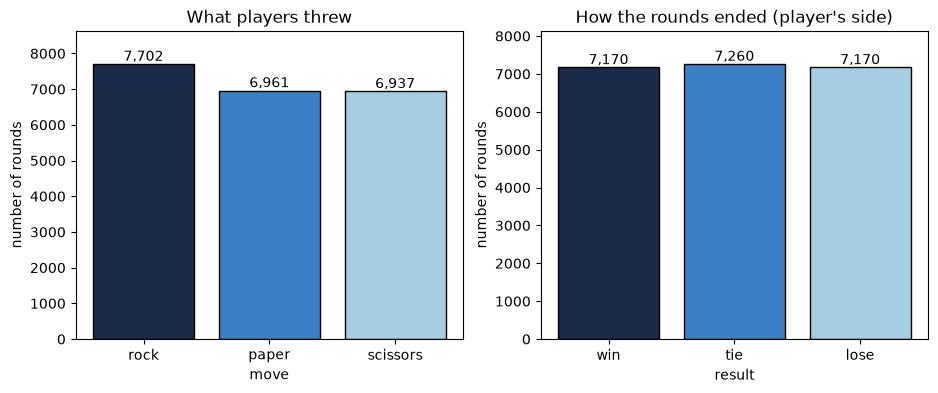

In [8]:
def labelled_bars(ax, names, values, title, xlabel, ylabel):
    """A bar chart with the count written on each bar."""
    bars = ax.bar(names, values, color=SHADES, edgecolor="black")
    ax.bar_label(bars, labels=[f"{value:,}" for value in values])
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.margins(y=0.12)  # room for the labels


throws = games["c"].map(NAMES).value_counts().reindex(NAMES.values())
results = games["result"].value_counts().reindex(["win", "tie", "lose"])
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
labelled_bars(left, throws.index, throws.values, "What players threw", "move", "number of rounds")
labelled_bars(right, results.index, results.values, "How the rounds ended (player's side)", "result", "number of rounds")
plt.show()

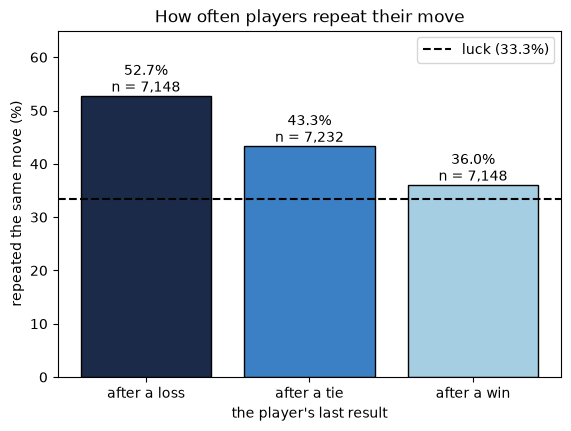

In [9]:
previous = games.groupby("id")[["c", "result"]].shift(1)  # the round before each round, from the same player
repeated = games["c"] == previous["c"]
repeat_rate = repeated.groupby(previous["result"]).agg(["mean", "size"]).reindex(["lose", "tie", "win"])

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(["after a loss", "after a tie", "after a win"], repeat_rate["mean"] * 100, color=SHADES, edgecolor="black")
ax.bar_label(bars, labels=[f"{share:.1%}\nn = {n:,}" for share, n in zip(repeat_rate["mean"], repeat_rate["size"])])
ax.axhline(100 / 3, linestyle="--", color="black", label=f"luck ({1 / 3:.1%})")
ax.set(title="How often players repeat their move", xlabel="the player's last result", ylabel="repeated the same move (%)", ylim=(0, 65))
ax.legend()
plt.show()

Heatmaps: for each last result, how often each next move follows each last move. Every row adds up to 100%.
If players were random, every cell would be about 33%.

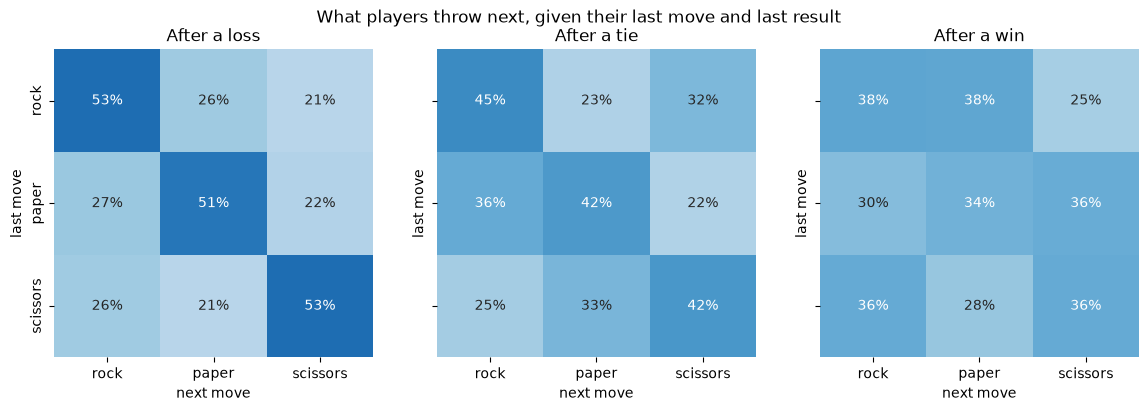

In [10]:
last = games.groupby("id")[["choice", "result"]].shift(1)
words = {"r": "rock", "p": "paper", "s": "scissors"}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, last_result, title in zip(axes, ["lose", "tie", "win"], ["After a loss", "After a tie", "After a win"]):
    after = last["result"] == last_result
    follows = pd.crosstab(last["choice"][after], games["choice"][after], normalize="index")
    follows = follows.reindex(index=list(words), columns=list(words)).rename(index=words, columns=words)
    sns.heatmap(follows, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=0.7, cbar=False, ax=ax)
    ax.set(title=title, xlabel="next move", ylabel="last move")
fig.suptitle("What players throw next, given their last move and last result")
plt.show()

## 5. Features
The brain sees the last two rounds, but not as raw rock, paper and scissors. It gets three small numbers, each coded **relative to the player**:
- `o_rel1`: how the last round went. It is (opponent move - player move) mod 3, so 1 = the player lost, 2 = the player won, 0 = a tie.
- `shift1`: how the player moved between the two rounds before: 0 = stayed, 1 = stepped *up* to the move that beats their old move, 2 = stepped *down*.
- `o_rel2`: how the round before that went, coded like `o_rel1`.

The target `shift` is the same idea for the next move: **stay, up or down**, not rock, paper or scissors.

**Why relative?** Rock-paper-scissors is a circle: turn every move one step and the game is the same. "Stay after a loss" is one habit whether the player lost with rock, paper or scissors, so one relative label learns from all three at once. That is three times the examples for each pattern. To get the real move back, we shift the player's last move.

**Why is `input` dropped?** The study's original file has an `input` column. It only holds the player's previous choice, which we already know from the row before, so it adds nothing. We left it out of the CSV.

In [11]:
rows = add_features(games)
display(rows.head())
print(f"model rows (rounds with a 2-round history): {len(rows):,}")
counts = rows["shift"].map(dict(enumerate(SHIFT_NAMES))).value_counts().reindex(SHIFT_NAMES)
display(pd.DataFrame({"rows": counts, "share": counts / counts.sum()}).round(3))

,id,period,choice,o_rel1,shift1,o_rel2,shift
2,1,3,s,1,0,0,0
3,1,4,s,2,0,1,0
4,1,5,s,2,0,2,0
5,1,6,r,2,0,2,1
6,1,7,s,0,1,2,2


model rows (rounds with a 2-round history): 21,456


,rows,share
shift,,
stay,9437,0.440
up,6043,0.282
down,5976,0.279


## 6. Split by player, not by row
The lab notebooks split rows at random with `train_test_split`. We split by player instead, because the question is whether the brain can predict **new people**.
Every score below uses `GroupKFold`: all the rounds of one player stay together, on the training side or on the test side, never on both. That is our **evidence of predictability on unseen players**.
A random split would put rounds of the same person on both sides, which can flatter a model that has learned one person's habits. With only three simple features the effect should be small. The last two lines of the cell measure it with the same Decision Tree.

In [12]:
X, y, groups = rows[FEATURES], rows["shift"], rows["id"]
for number, (train, test) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), start=1):
    shared = set(groups.iloc[train]) & set(groups.iloc[test])
    print(f"fold {number}: {groups.iloc[train].nunique()} players train, {groups.iloc[test].nunique()} players test, {len(shared)} players on both sides")
random_split = cross_val_score(brain_pipeline("dt"), X, y, cv=KFold(n_splits=5, shuffle=True, random_state=42))
player_split = cross_val_score(brain_pipeline("dt"), X, y, groups=groups, cv=GroupKFold(n_splits=5))
print(f"Decision Tree scored on a random split of the rounds (players on both sides): {random_split.mean():.1%}")
print(f"Decision Tree scored on a split by player (GroupKFold):                       {player_split.mean():.1%}")

fold 1: 57 players train, 15 players test, 0 players on both sides
fold 2: 57 players train, 15 players test, 0 players on both sides
fold 3: 58 players train, 14 players test, 0 players on both sides
fold 4: 58 players train, 14 players test, 0 players on both sides
fold 5: 58 players train, 14 players test, 0 players on both sides
Decision Tree scored on a random split of the rounds (players on both sides): 46.1%
Decision Tree scored on a split by player (GroupKFold):                       45.5%


## 7. Five models, and three yardsticks
The brain is a scikit-learn `Pipeline` of two steps, like Lab 8: **encode** the three features, then **fit a model**.
Most models get one-hot columns (a 0/1 column for every value of a feature). Categorical Naive Bayes wants category numbers, so it gets an ordinal encoder.
- **dt**: Decision Tree (Lab 4). A flow chart of yes/no questions about the features.
- **svm**: Support Vector Machine with the RBF kernel (Lab 8). Draws a curved boundary between the classes.
- **logreg**: Logistic Regression (Lab 6). Adds up weighted features into a probability for each class.
- **nb**: Categorical Naive Bayes. Counts how often each feature value goes with each class. (Lab 7 used the Gaussian kind, for measured numbers; ours are categories.)
- **perceptron**: Perceptron (Lab 6). A straight-line boundary that is nudged only when it makes a mistake.

Every model is scored the same way, with the 5-fold `GroupKFold` from step 6, so each score is **evidence of predictability on unseen players**.
`evaluate` makes one pass per model and keeps the prediction for every round, made while that round's player was in the test fold.
Precision, recall and F1 are macro averages: worked out for stay, up and down separately, then averaged.

The SVM runs here without its `probability` option. It makes the same predictions, but the option makes it much slower. The price: the SVM has no ROC curve below.

In [13]:
def evaluate(pipeline, X, y, groups):
    """One pass of 5-fold GroupKFold. Returns the accuracy of each fold, and for every round the prediction
    (and the probabilities, if the model has them) made while that round's player was in the test fold."""
    scores = []
    predicted = np.zeros(len(y), dtype=int)
    probabilities = np.zeros((len(y), 3)) if hasattr(pipeline, "predict_proba") else None
    for train, test in GroupKFold(n_splits=5).split(X, y, groups):
        model = clone(pipeline).fit(X.iloc[train], y.iloc[train])
        predicted[test] = model.predict(X.iloc[test])
        scores.append(accuracy_score(y.iloc[test], predicted[test]))
        if probabilities is not None:
            probabilities[test] = model.predict_proba(X.iloc[test])
    return scores, predicted, probabilities


def micro_roc(y, probabilities):
    """The ROC curve over all three classes at once (each class against the rest), or None if the model has no probabilities."""
    if probabilities is None:
        return None
    fpr, tpr, _ = roc_curve(label_binarize(y, classes=[0, 1, 2]).ravel(), probabilities.ravel())
    return fpr, tpr, auc(fpr, tpr)


def result_row(name, scores, predicted, probabilities, y):
    """One row of the comparison table, worked out from the predictions made on players the model had not seen."""
    return {
        "model": name,
        "accuracy": accuracy_score(y, predicted),
        "precision": precision_score(y, predicted, average="macro", zero_division=0),
        "recall": recall_score(y, predicted, average="macro", zero_division=0),
        "f1": f1_score(y, predicted, average="macro", zero_division=0),
        "cv_scores": scores,
        "roc": micro_roc(y, probabilities),
        "cm": confusion_matrix(y, predicted, labels=[0, 1, 2]).tolist(),
    }

In [14]:
out_of_fold = {}  # model name -> (predictions, probabilities or None), kept for the metrics below
table_rows = []
for name in ["dt", "svm", "logreg", "nb", "perceptron"]:
    pipeline = brain_pipeline(name)
    if name == "svm":
        pipeline.set_params(model__probability=False)  # see the note above
    scores, predicted, probabilities = evaluate(pipeline, X, y, groups)
    out_of_fold[name] = (predicted, probabilities)
    table_rows.append(result_row(name, scores, predicted, probabilities, y))
RESULTS = pd.DataFrame(table_rows)
BASELINES = {"luck": 1 / 3, "always-rock": FACTS["always_rock_model_rows"], "always-repeat": FACTS["always_repeat_model_rows"]}
BEST_BRAIN = RESULTS.loc[RESULTS["accuracy"].idxmax(), "model"]  # the highest accuracy; the first one on a tie

## 8. Comparison table and bar chart
Everything in percent, on the same rounds (the model rows). The three yardsticks have an accuracy only, since they are not trained models:
**luck** guesses at random, **always-rock** always predicts rock, **always-repeat** always predicts the player's last move again.

Why do dt and svm score the same? The three features can only make 3 x 3 x 3 = 27 different situations. The line under the table checks a guess: that both models just predict, for each situation, the shift that came next most often among the training players. That is a plain **lookup table**, rebuilt in every fold from the training players only.
If the lookup table gives the same answers, a fancier model has nothing more to find in these features.

In [15]:
def lookup_table_predictions(situation, y, groups):
    """The plain table: in each fold, predict for every situation the shift that came next most often among the training players."""
    predicted = np.zeros(len(y), dtype=int)
    for train, test in GroupKFold(n_splits=5).split(situation, y, groups):
        counts = pd.crosstab(situation.iloc[train], y.iloc[train])  # rows: situations, columns: stay, up, down
        most_common = counts.idxmax(axis=1)  # a tie goes to the lowest shift
        overall = y.iloc[train].mode()[0]  # for a situation the training players never showed
        predicted[test] = most_common.reindex(situation.iloc[test].to_numpy()).fillna(overall).astype(int).to_numpy()
    return predicted


table = RESULTS.set_index("model")[["accuracy", "precision", "recall", "f1"]]
table = pd.concat([table, pd.DataFrame({"accuracy": BASELINES})])
print((table * 100).round(1).to_string(na_rep="-"))
situation = X["o_rel1"] * 9 + X["shift1"] * 3 + X["o_rel2"]  # one number for each combination of the three features
lookup = lookup_table_predictions(situation, y, groups)
dt_predicted = out_of_fold["dt"][0]
print(f"\ndt and svm made the same prediction on {(dt_predicted == out_of_fold['svm'][0]).mean():.1%} of the rounds; "
      f"the {situation.nunique()}-situation lookup table agrees with dt on {(lookup == dt_predicted).mean():.1%} and scores {(lookup == y).mean():.1%} itself")

               accuracy  precision  recall    f1
dt                 45.5       42.4    39.9  38.5
svm                45.5       42.4    39.9  38.5
logreg             44.7       40.3    38.2  35.6
nb                 44.8       40.5    38.3  35.7
perceptron         37.9       37.3    36.6  33.9
luck               33.3          -       -     -
always-rock        35.6          -       -     -
always-repeat      44.0          -       -     -

dt and svm made the same prediction on 100.0% of the rounds; the 27-situation lookup table agrees with dt on 100.0% and scores 45.5% itself


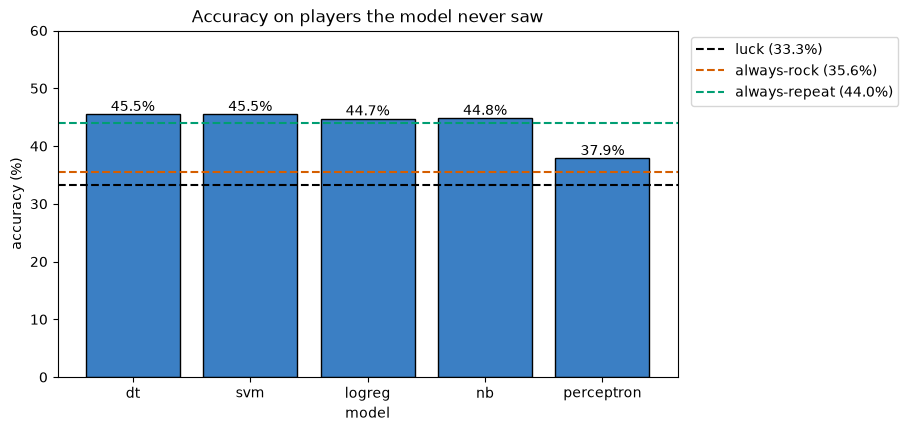

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(RESULTS["model"], RESULTS["accuracy"] * 100, color=SHADES[1], edgecolor="black")
ax.bar_label(bars, labels=[f"{accuracy:.1%}" for accuracy in RESULTS["accuracy"]])
for (name, value), colour in zip(BASELINES.items(), BASELINE_COLOURS):
    ax.axhline(value * 100, linestyle="--", color=colour, label=f"{name} ({value:.1%})")
ax.set(title="Accuracy on players the model never saw", xlabel="model", ylabel="accuracy (%)", ylim=(0, 60))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

## 9. Metrics for the best model
The **confusion matrix** counts, for each true shift (rows), what the model predicted (columns). The **classification report** gives precision, recall and F1 for each shift.
Then the hook again: **accuracy right after a loss**, on exactly those rounds, next to the yardsticks on the same rounds.

best model: dt


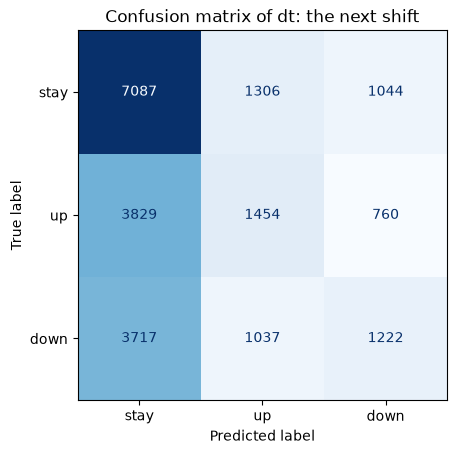

              precision    recall  f1-score   support

        stay       0.48      0.75      0.59      9437
          up       0.38      0.24      0.30      6043
        down       0.40      0.20      0.27      5976

    accuracy                           0.46     21456
   macro avg       0.42      0.40      0.39     21456
weighted avg       0.43      0.46      0.42     21456

accuracy right after a loss (n = 7,130):
  (7,130 of the 7,148 in the hook: the model needs 2 rounds of history)
  dt             54.3%
  always-repeat  52.7%
  always-rock    35.8%
  luck           33.3%


In [17]:
predicted = out_of_fold[BEST_BRAIN][0]
print("best model:", BEST_BRAIN)
ConfusionMatrixDisplay.from_predictions(y, predicted, display_labels=SHIFT_NAMES, cmap="Blues", colorbar=False)
plt.title(f"Confusion matrix of {BEST_BRAIN}: the next shift")
plt.show()
print(classification_report(y, predicted, target_names=SHIFT_NAMES, zero_division=0))

after_loss = (rows["o_rel1"] == 1).to_numpy()  # o_rel1 = 1: the player lost the last round
shares = {
    BEST_BRAIN: accuracy_score(y[after_loss], predicted[after_loss]),
    "always-repeat": (y[after_loss] == 0).mean(),
    "always-rock": (rows["choice"][after_loss] == "r").mean(),
    "luck": 1 / 3,
}
print(f"accuracy right after a loss (n = {after_loss.sum():,}):")
print(f"  ({after_loss.sum():,} of the {FACTS['n_after_loss']:,} in the hook: the model needs 2 rounds of history)")
for name, share in shares.items():
    print(f"  {name:14s}{share:6.1%}")

**ROC curves.** For each shift in turn, the curve for "this shift against the other two" (that is what `label_binarize` sets up).
The dotted line is chance; the more a curve bows towards the top left, the better. This is the best model that has probabilities.

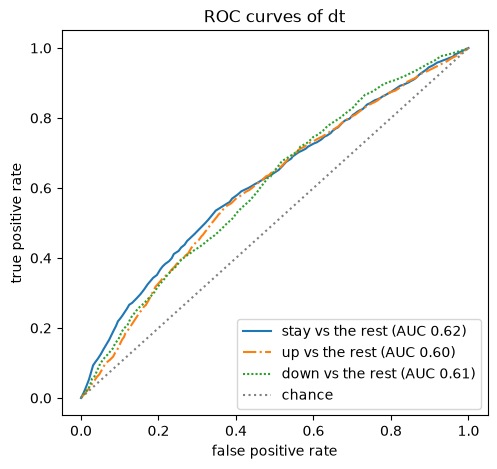

In [18]:
with_probabilities = RESULTS[RESULTS["roc"].notna()]
roc_model = with_probabilities.loc[with_probabilities["accuracy"].idxmax(), "model"]
shift_onehot = label_binarize(y, classes=[0, 1, 2])
fig, ax = plt.subplots(figsize=(5.5, 5))
for k, shift_name in enumerate(SHIFT_NAMES):
    fpr, tpr, _ = roc_curve(shift_onehot[:, k], out_of_fold[roc_model][1][:, k])
    ax.plot(fpr, tpr, linestyle=LINE_STYLES[k], label=f"{shift_name} vs the rest (AUC {auc(fpr, tpr):.2f})")
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="chance")
ax.set(title=f"ROC curves of {roc_model}", xlabel="false positive rate", ylabel="true positive rate")
ax.legend(loc="lower right")
plt.show()

## 10. Tuning with GridSearchCV
`GridSearchCV` tries every setting in a grid, scores each one with the same 5-fold `GroupKFold`, and keeps the best. Then it refits that best setting on all the rounds it was given.
- **dt**: how deep the tree may grow, and the smallest number of rounds allowed in a leaf.
- **logreg**: `C`, how loosely the model may fit the training rounds (bigger is looser).
- **svm**: `C` too. The SVM is slow, so it is tuned and fitted on a small group of players only (the first ones in the file). The printed line says how many players and rounds.

Each line shows the best setting, its accuracy as **mean ± std** over the folds, and how many settings tie for best (a tie means the grid cannot tell them apart). Under them are the three yardsticks **on the same rounds**.
The best setting is picked and scored on the same folds, so its score is slightly optimistic.
The SVM line cannot be compared with the others: it is scored on that small group only, in very small folds, so it is noisier, and its yardsticks are different.

In [19]:
GRIDS = {
    "dt": {"model__max_depth": [3, 4, 5, 6, 8], "model__min_samples_leaf": [1, 20, 50]},
    "logreg": {"model__C": [0.1, 1, 10]},
    "svm": {"model__C": [0.5, 1, 2]},
}


def print_yardsticks(label, subset):
    """Luck, always-rock and always-repeat on the same rounds as the score printed above them."""
    shares = {"luck": 1 / 3, "always-rock": (subset["choice"] == "r").mean(), "always-repeat": (subset["shift"] == 0).mean()}
    print(f"  yardsticks on {label}: " + ", ".join(f"{name} {share:.1%}" for name, share in shares.items()))


def tune(name, pipeline, X, y, groups, note=""):
    """GridSearchCV with the 5-fold GroupKFold. Prints the best settings and their accuracy as mean ± std over the folds."""
    search = GridSearchCV(pipeline, GRIDS[name], cv=GroupKFold(n_splits=5), scoring="accuracy").fit(X, y, groups=groups)
    best, ranks = search.best_index_, search.cv_results_["rank_test_score"]
    mean, std = search.cv_results_["mean_test_score"][best], search.cv_results_["std_test_score"][best]
    print(f"{name}: best {search.best_params_}, accuracy {mean:.1%} ± {std:.1%} over 5 folds; {(ranks == 1).sum()} of {len(ranks)} settings tie for best{note}")
    return search


search_dt = tune("dt", brain_pipeline("dt"), X, y, groups)
search_logreg = tune("logreg", brain_pipeline("logreg"), X, y, groups)
print_yardsticks(f"all {len(rows):,} rounds", rows)

first_players = sorted(rows["id"].unique())[:20]
small = rows[rows["id"].isin(first_players)]
note = f" (tuned on the first {len(first_players)} players, {len(small):,} rounds)"
search_svm = tune("svm", brain_pipeline("svm").set_params(model__probability=False), small[FEATURES], small["shift"], small["id"], note)
print_yardsticks(f"those {len(small):,} rounds", small)
# the live SVM keeps its probability option: the game shows that percentage next to the move
live_svm = brain_pipeline("svm").set_params(model__C=search_svm.best_params_["model__C"]).fit(small[FEATURES], small["shift"])

dt: best {'model__max_depth': 6, 'model__min_samples_leaf': 1}, accuracy 45.5% ± 1.4% over 5 folds; 6 of 15 settings tie for best


logreg: best {'model__C': 0.1}, accuracy 44.7% ± 1.7% over 5 folds; 3 of 3 settings tie for best
  yardsticks on all 21,456 rounds: luck 33.3%, always-rock 35.6%, always-repeat 44.0%


svm: best {'model__C': 0.5}, accuracy 47.3% ± 5.2% over 5 folds; 3 of 3 settings tie for best (tuned on the first 20 players, 5,960 rounds)
  yardsticks on those 5,960 rounds: luck 33.3%, always-rock 35.0%, always-repeat 46.0%


**The brains.** These are what the live game plays against. Each model is wrapped in `ModelBrain`: it turns a round history into the three features, asks the model for the likeliest next shift, and turns that into a move.
`personal` learns only from the current player's own game, and `random` guesses (the luck yardstick). `BEST_BRAIN` is the model with the highest accuracy in step 8.

**Careful with `svm`.** The SVM in the comparison table uses all the players and has no probabilities. The `svm` brain that plays live is a different fit: the first few players only (that is how it stays quick), with the `C` picked in step 10, and with probabilities so the game can show a percentage.
So the table's SVM score does not describe it. The last lines of the cell score it on the players it never saw, next to always-repeat on those same rounds.

In [20]:
BRAINS = {
    "dt": ModelBrain(search_dt.best_estimator_, "dt"),
    "logreg": ModelBrain(search_logreg.best_estimator_, "logreg"),
    "svm": ModelBrain(live_svm, "svm"),
    "nb": ModelBrain(brain_pipeline("nb").fit(X, y), "nb"),
    "perceptron": ModelBrain(brain_pipeline("perceptron").fit(X, y), "perceptron"),
    "personal": PersonalBrain(),
    "random": RandomBrain(),
}
print("brains ready:", ", ".join(BRAINS))
print("best brain:", BEST_BRAIN)

other_players = rows[~rows["id"].isin(first_players)]  # the players the live svm never saw
likeliest = live_svm.classes_[live_svm.predict_proba(other_players[FEATURES]).argmax(axis=1)]  # the game plays the likeliest shift from the probabilities
LIVE_SVM = {"accuracy": float((likeliest == other_players["shift"]).mean()), "always_repeat": float((other_players["shift"] == 0).mean()), "n": len(other_players)}
print(f"live svm (fitted on {len(first_players)} players), scored on the other {other_players['id'].nunique()} players ({LIVE_SVM['n']:,} rounds): "
      f"accuracy {LIVE_SVM['accuracy']:.1%}, always-repeat {LIVE_SVM['always_repeat']:.1%}")

brains ready: dt, logreg, svm, nb, perceptron, personal, random
best brain: dt


live svm (fitted on 20 players), scored on the other 52 players (15,496 rounds): accuracy 43.9%, always-repeat 43.2%


## 11. Cross-validation: mean ± std
The five scores of step 7 are cross-validation already (`cross_val_score` in the labs does the same). Here is each model's mean and spread over the folds, each fold being a different group of players the model had not seen.
A small std means the model does about equally well on every group of players.
Compare the dt and logreg lines with the tuned lines in step 10: where they match, tuning found nothing better than the default settings.
Always-repeat is scored on the same test players, fold by fold. A model only really beats it if it is ahead in most folds, not just on average, so the last line counts the folds where dt is ahead.

In [21]:
for row in RESULTS.itertuples():
    scores = np.array(row.cv_scores)
    print(f"{row.model}: {scores.mean():.1%} ± {scores.std():.1%} over 5 folds")
print_yardsticks(f"the same {len(rows):,} rounds", rows)
repeat_folds = [(y.iloc[test] == 0).mean() for _, test in GroupKFold(n_splits=5).split(X, y, groups)]  # always-repeat on each test fold
dt_folds = RESULTS.set_index("model").loc["dt", "cv_scores"]
print(f"always-repeat: {np.mean(repeat_folds):.1%} ± {np.std(repeat_folds):.1%} over 5 folds (the same test players)")
print(f"dt beats always-repeat in {sum(dt > repeat for dt, repeat in zip(dt_folds, repeat_folds))} of {len(repeat_folds)} folds")

dt: 45.5% ± 1.4% over 5 folds
svm: 45.5% ± 1.4% over 5 folds
logreg: 44.7% ± 1.7% over 5 folds
nb: 44.8% ± 1.7% over 5 folds
perceptron: 37.9% ± 3.7% over 5 folds
  yardsticks on the same 21,456 rounds: luck 33.3%, always-rock 35.6%, always-repeat 44.0%
always-repeat: 44.0% ± 3.3% over 5 folds (the same test players)
dt beats always-repeat in 3 of 5 folds


## 12. Learning curve: how many players does the brain need?
Train the Decision Tree on the first few players, then more and more, and score it each time on players it has not seen.
If the unseen-player line were still climbing at the end, more players would help. The dashed lines are the yardsticks.

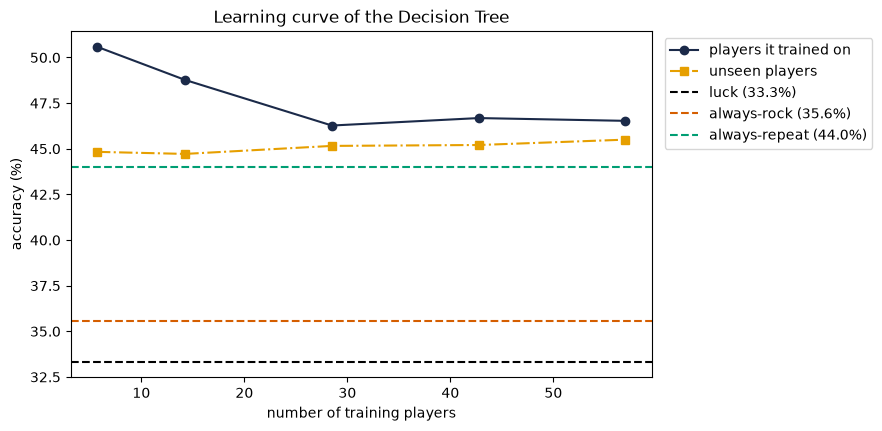

  5.7 training players: 50.6% on them, 44.8% on unseen players
 14.2 training players: 48.8% on them, 44.7% on unseen players
 28.5 training players: 46.3% on them, 45.2% on unseen players
 42.7 training players: 46.7% on them, 45.2% on unseen players
 57.0 training players: 46.5% on them, 45.5% on unseen players
on unseen players: +0.7 points from 5.7 to 57.0 training players


In [22]:
rows_per_player = len(rows) // rows["id"].nunique()
sizes, train_scores, unseen_scores = learning_curve(
    brain_pipeline("dt"), X, y, groups=groups, cv=GroupKFold(n_splits=5), train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], shuffle=False)
players = sizes / rows_per_player  # the rows are sorted by player, so each training set is the first few whole players
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(players, train_scores.mean(axis=1) * 100, marker="o", linestyle="-", color="#1b2a49", label="players it trained on")
ax.plot(players, unseen_scores.mean(axis=1) * 100, marker="s", linestyle="-.", color="#e69f00", label="unseen players")
for (name, value), colour in zip(BASELINES.items(), BASELINE_COLOURS):
    ax.axhline(value * 100, linestyle="--", color=colour, label=f"{name} ({value:.1%})")
ax.set(title="Learning curve of the Decision Tree", xlabel="number of training players", ylabel="accuracy (%)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()
for count, seen, unseen in zip(players, train_scores.mean(axis=1), unseen_scores.mean(axis=1)):
    print(f"{count:5.1f} training players: {seen:.1%} on them, {unseen:.1%} on unseen players")
gain = 100 * (unseen_scores.mean(axis=1)[-1] - unseen_scores.mean(axis=1)[0])
print(f"on unseen players: {gain:+.1f} points from {players[0]:.1f} to {players[-1]:.1f} training players")

## 13. Why the Perceptron is the odd one out
The Perceptron changes its line only when it gets a round wrong. Here the answers are noisy and overlap: the same situation is followed by different shifts, from different people. So it is always getting some rounds wrong, its line keeps moving, and it **never settles**.
Where it ends up depends on the order it sees the rows, which the random seed sets. Below, the same Perceptron with several different seeds, next to Logistic Regression. Logistic Regression looks at all the rounds at once and settles on one answer, so it gives the same score every time.

perceptron seed 0: 36.5% ± 4.4% over 5 folds
perceptron seed 1: 40.5% ± 4.4% over 5 folds


perceptron seed 2: 39.2% ± 2.8% over 5 folds


perceptron seed 3: 39.9% ± 3.5% over 5 folds
perceptron seed 4: 41.0% ± 3.5% over 5 folds
logreg (any seed): 44.7%


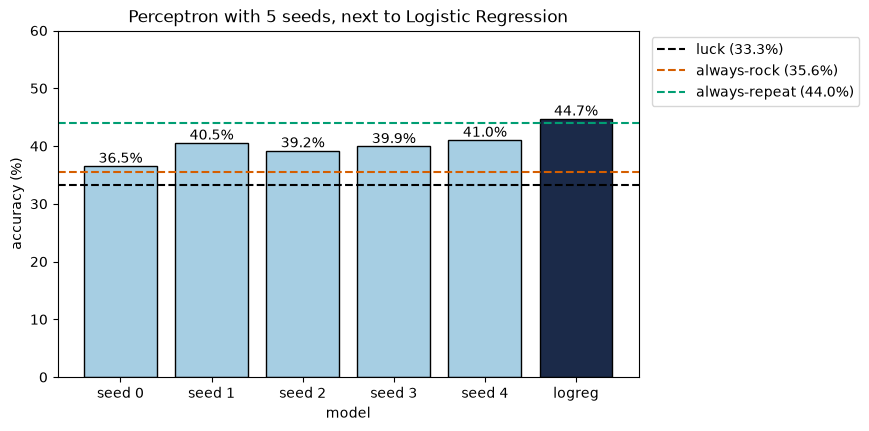

In [23]:
seed_means = []
for seed in range(5):
    scores = cross_val_score(brain_pipeline("perceptron").set_params(model__random_state=seed), X, y, groups=groups, cv=GroupKFold(n_splits=5))
    seed_means.append(scores.mean())
    print(f"perceptron seed {seed}: {scores.mean():.1%} ± {scores.std():.1%} over 5 folds")
logreg_mean = float(np.mean(RESULTS.set_index("model").loc["logreg", "cv_scores"]))
print(f"logreg (any seed): {logreg_mean:.1%}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar([f"seed {seed}" for seed in range(5)] + ["logreg"], np.array(seed_means + [logreg_mean]) * 100,
              color=[SHADES[2]] * 5 + [SHADES[0]], edgecolor="black")
ax.bar_label(bars, labels=[f"{mean:.1%}" for mean in seed_means + [logreg_mean]])
for (name, value), colour in zip(BASELINES.items(), BASELINE_COLOURS):
    ax.axhline(value * 100, linestyle="--", color=colour, label=f"{name} ({value:.1%})")
ax.set(title=f"Perceptron with {len(seed_means)} seeds, next to Logistic Regression", xlabel="model", ylabel="accuracy (%)", ylim=(0, 60))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

## 14. The early rounds
The accuracy above is an average over all the rounds of unseen players. A real game starts with no history at all, so the first rounds matter too.
Two brains are shown, each next to the yardsticks **on the same rounds**:
- **Personal** learns only from this one player's own game: a small table of counts, one cell per kind of last round and next shift, every cell starting at 1. It needs no training data and works from round 2. Here it is replayed round by round over all the players.
- The **Decision Tree** is the one from step 7, using its predictions on unseen players. It needs two rounds of history, so it starts at round 3.

In [24]:
def early_numbers(last_round):
    """The numbers for the first rounds, printed with their n and returned for metrics.json."""
    rock, repeat, personal, n = early_window(games, last_round)
    in_window = (rows["period"] <= last_round).to_numpy()  # the model rows start at round 3
    tree = (out_of_fold["dt"][0][in_window] == y[in_window]).mean()
    print(f"rounds 2-{last_round}, n = {n:,}: luck {1 / 3:.1%} | always-rock {rock:.1%} | always-repeat {repeat:.1%} | personal {personal:.1%}")
    print(f"rounds 3-{last_round}, n = {in_window.sum():,}: luck {1 / 3:.1%} | always-rock {(rows['choice'][in_window] == 'r').mean():.1%} | "
          f"always-repeat {(y[in_window] == 0).mean():.1%} | decision tree {tree:.1%}")
    return {"always_rock": float(rock), "always_repeat": float(repeat), "personal": float(personal), "n": int(n),
            "dt": float(tree), "n_dt": int(in_window.sum())}


EARLY = {f"2-{last_round}": early_numbers(last_round) for last_round in (10, 20)}

rounds 2-10, n = 648: luck 33.3% | always-rock 34.9% | always-repeat 39.2% | personal 40.0%
rounds 3-10, n = 576: luck 33.3% | always-rock 33.7% | always-repeat 39.4% | decision tree 39.6%
rounds 2-20, n = 1,368: luck 33.3% | always-rock 37.0% | always-repeat 41.5% | personal 42.4%
rounds 3-20, n = 1,296: luck 33.3% | always-rock 36.6% | always-repeat 41.7% | decision tree 42.1%


## 15. How much does the Personal brain gain as the game goes on?
Linear Regression (Lab 2). Each dot is the share of players the Personal brain guessed right in that round. The straight line is a Linear Regression of "right" (100) or "wrong" (0) on the round number. Its slope is how many points the score rises for every 100 more rounds.
But that whole slope is not the brain's own gain: players also get more repetitive as a game goes on, so even **always-repeat** scores higher in later rounds. So we fit the same straight line to always-repeat's hits on the same rounds, and subtract.
The difference is how much more the Personal brain gains than the always-repeat yardstick does. The flat dashed lines are the other two yardsticks over the same rounds.

Personal brain: +3.2 points per 100 rounds (n = 21,528 predictions)
always-repeat:  +1.3 points per 100 rounds (the same 21,528 rounds)
Personal's own gain over always-repeat: +1.8 points per 100 rounds


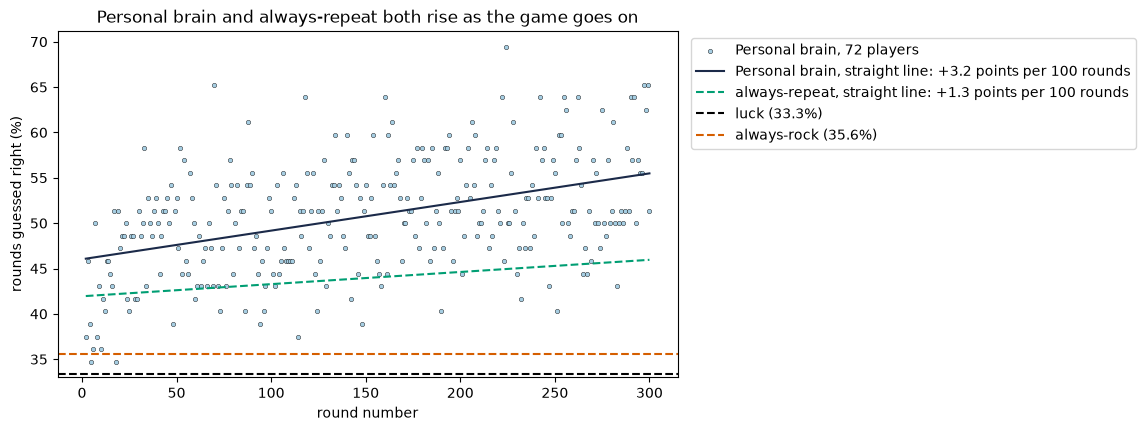

In [25]:
def slope_per_100(hits):
    """Fit a straight line to 'right' (100) or 'wrong' (0) against the round number. Returns the line and its slope in points per 100 rounds."""
    line = LinearRegression().fit(hits[["round"]], hits["hit"] * 100)
    return line, float(line.coef_[0]) * 100


hits = replay_hits(games, PersonalBrain(), games["period"].max())
later = games["period"] >= 2  # the same rounds the Personal brain was scored on
last_move = games.groupby("id")["c"].shift(1)  # the player's previous move
repeat_hits = pd.DataFrame({"round": games["period"][later], "hit": (games["c"] == last_move)[later].astype(int)})  # always-repeat is right when the move is the previous one
line, SLOPE_PER_100 = slope_per_100(hits)
repeat_line, REPEAT_SLOPE_PER_100 = slope_per_100(repeat_hits)
print(f"Personal brain: {SLOPE_PER_100:+.1f} points per 100 rounds (n = {len(hits):,} predictions)")
print(f"always-repeat:  {REPEAT_SLOPE_PER_100:+.1f} points per 100 rounds (the same {len(repeat_hits):,} rounds)")
print(f"Personal's own gain over always-repeat: {SLOPE_PER_100 - REPEAT_SLOPE_PER_100:+.1f} points per 100 rounds")

flat_yardsticks = {"luck": 1 / 3, "always-rock": (games["c"] == 0)[later].mean()}
by_round = hits.groupby("round")["hit"].mean() * 100
rounds = by_round.index.to_frame(name="round")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(by_round.index, by_round, s=10, color=SHADES[2], edgecolor="black", linewidth=0.3, label=f"Personal brain, {games['id'].nunique()} players")
ax.plot(rounds["round"], line.predict(rounds), color=SHADES[0], label=f"Personal brain, straight line: {SLOPE_PER_100:+.1f} points per 100 rounds")
ax.plot(rounds["round"], repeat_line.predict(rounds), linestyle="--", color=BASELINE_COLOURS[2], label=f"always-repeat, straight line: {REPEAT_SLOPE_PER_100:+.1f} points per 100 rounds")
for (name, value), colour in zip(flat_yardsticks.items(), BASELINE_COLOURS):
    ax.axhline(value * 100, linestyle="--", color=colour, label=f"{name} ({value:.1%})")
ax.set(title="Personal brain and always-repeat both rise as the game goes on", xlabel="round number", ylabel="rounds guessed right (%)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

## 16. One new example
A player has thrown two rounds so far: round 1, rock against scissors (a win), and round 2, rock against paper (a loss).
We turn that history into the three features and ask the best brain what comes next. CHANAKYA then plays the move that beats the prediction.

In [26]:
history = [(0, 2), (0, 1)]  # (player's move, CHANAKYA's move): rock vs scissors, then rock vs paper
for number, (player, bot) in enumerate(history, start=1):
    print(f"round {number}: you threw {NAMES[player]}, CHANAKYA threw {NAMES[bot]}: {outcome(player, bot)}")
display(pd.DataFrame([history_features(history)]))
decision = decide(history, BEST_BRAIN, BRAINS)
how_sure = "" if decision["prob"] is None else f" (probability {decision['prob']:.0%})"
print(f"the {decision['source']} brain expects you to throw {NAMES[decision['predicted_move']]} next{how_sure}")
print(f"CHANAKYA plays {NAMES[decision['bot_move']]}, the move that beats it")

round 1: you threw rock, CHANAKYA threw scissors: win
round 2: you threw rock, CHANAKYA threw paper: lose


,o_rel1,shift1,o_rel2
0,1,0,2


the dt brain expects you to throw rock next (probability 56%)
CHANAKYA plays paper, the move that beats it


## 17. All five models, side by side
The results table, then the comparison figure. Everything is scored on players the models had not seen.
- **Top left:** accuracy, precision, recall and F1 as bars. The dashed lines are **accuracy** yardsticks: compare them with the accuracy bars only, not with precision, recall or F1.
- **Top right:** the accuracy of each cross-validation fold, one dot per fold, with the same dashed yardsticks (on all the rounds). A short box means a steady model.
- **Bottom left:** ROC curves, for the models that give probabilities (the SVM here has none, and the Perceptron never does). Each curve is the micro-average over stay, up and down; the curve and AUC of each shift on its own are in step 9.
- **Bottom right:** the confusion matrix of the best model.

               accuracy  precision  recall    f1  cv mean  cv std
dt                 45.5       42.4    39.9  38.5     45.5     1.4
svm                45.5       42.4    39.9  38.5     45.5     1.4
logreg             44.7       40.3    38.2  35.6     44.7     1.7
nb                 44.8       40.5    38.3  35.7     44.8     1.7
perceptron         37.9       37.3    36.6  33.9     37.9     3.7
luck               33.3          -       -     -        -       -
always-rock        35.6          -       -     -        -       -
always-repeat      44.0          -       -     -        -       -


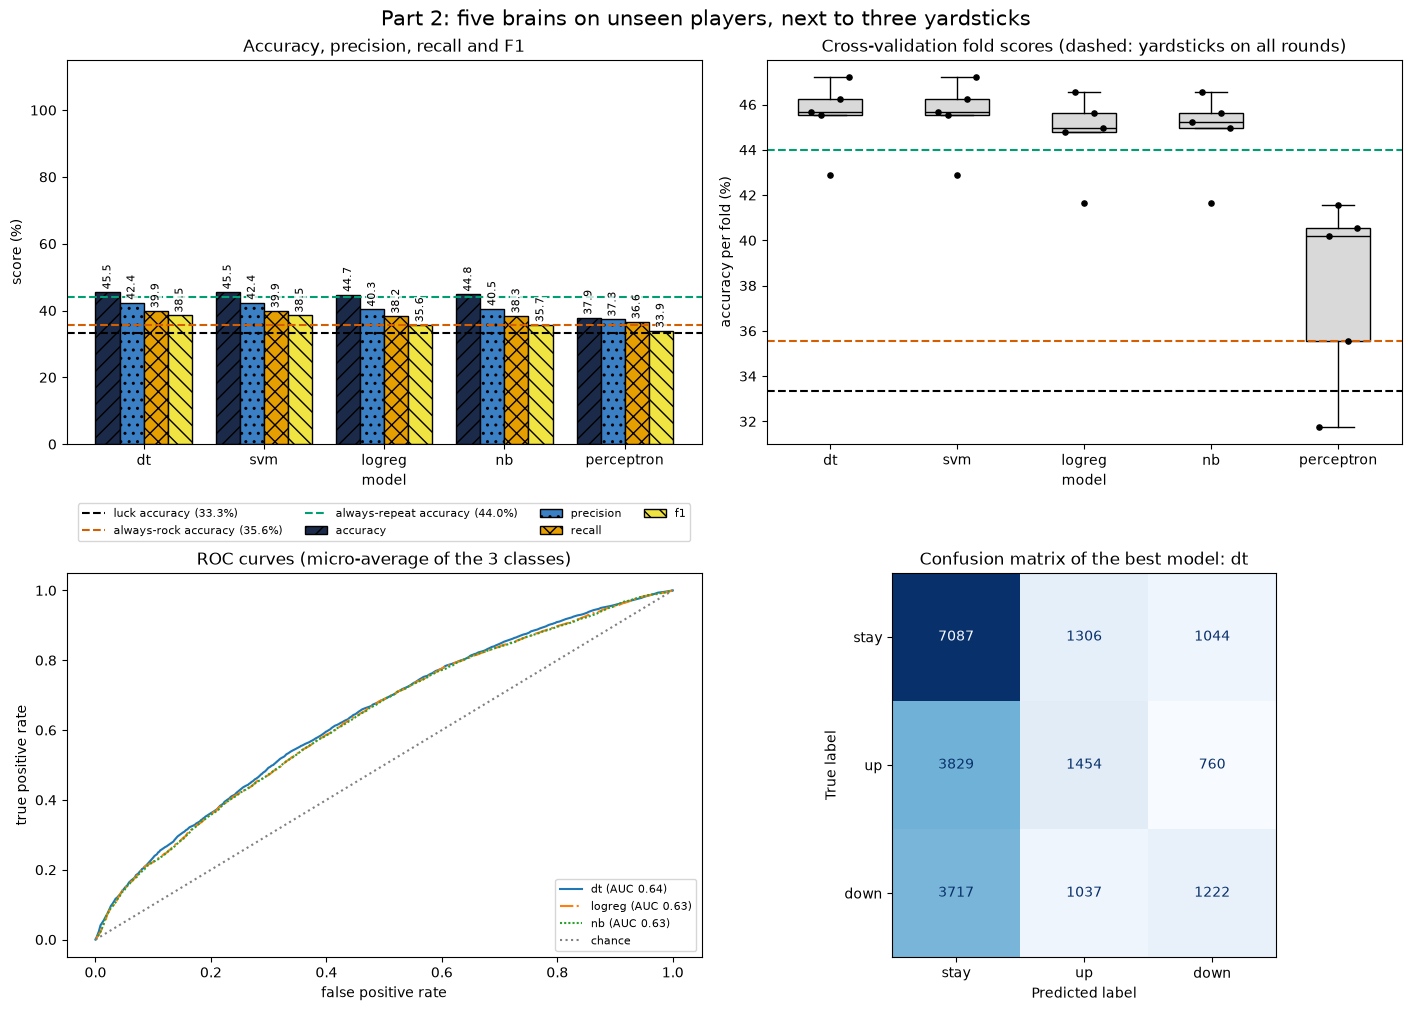

In [27]:
summary = RESULTS.set_index("model")[["accuracy", "precision", "recall", "f1"]].copy()
summary["cv mean"] = [np.mean(scores) for scores in RESULTS["cv_scores"]]
summary["cv std"] = [np.std(scores) for scores in RESULTS["cv_scores"]]
print((pd.concat([summary, pd.DataFrame({"accuracy": BASELINES})]) * 100).round(1).to_string(na_rep="-"))
fig = comparison_figure(RESULTS, "Part 2: five brains on unseen players, next to three yardsticks", BASELINES, labels=SHIFT_NAMES)
plt.show()

In [28]:
METRICS["brain_table"] = {row.model: float(row.accuracy) for row in RESULTS.itertuples()}
METRICS["brain_table"].update(luck=BASELINES["luck"], always_rock=BASELINES["always-rock"], always_repeat=BASELINES["always-repeat"])
METRICS["brain_early"] = EARLY
METRICS["personal_slope_per_100"] = SLOPE_PER_100
METRICS["repeat_slope_per_100"] = REPEAT_SLOPE_PER_100
METRICS["brain_table_live_svm"] = LIVE_SVM
METRICS["facts"] = FACTS
os.makedirs("build", exist_ok=True)
with open("build/metrics.json", "w") as file:
    json.dump(METRICS, file, indent=2)